**`Multiple-LinearRegression Model: Weather Prediction`**

*   `Problem Statement:` A meteorological station has recorded 366 daily weather observations including minimum temperature, rainfall, evaporation, sunshine hours, wind gust direction and speed, morning and afternoon wind directions and speeds, humidity, atmospheric pressure, cloud cover, morning and afternoon temperatures, whether it rained today, risk rainfall (`RISK_MM`), and whether it rained tomorrow. Your task is to build a Multiple Linear Regression model to predict the daily maximum temperature (`MaxTemp`) based on the remaining weather features. After fitting the model, you should inspect the regression coefficients, evaluate model accuracy using MAE, MSE, RMSE, R², Adjusted R², and MAPE, plot Actual vs Predicted values, and use the trained model to predict `MaxTemp` for new hypothetical weather input values.
    * Model formula: `y = a0 + a1*x1 + a2*x2 + ... + an*xn`
    * Where: `x1, x2, ..., xn` --> Independent variables (weather features)
    * `y` --> Dependent variable (`MaxTemp`)
    * `a1, a2, ..., an` --> coefficients / slopes / weights
    * `a0` --> constant / bias (intercept)

`Step-1: Import Necessary Libraries`

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

`Step-2: Import/Load the Dataset`

In [20]:
data = pd.read_csv(r"C:\Users\HP\Documents\GitHub\Machine-Learning-SEng4091\02_Supervised_Learning\weather.csv")

`Step-3: Dataset description/ Quick data check`
*   `*Important Note:*`
    * Dataset descriptions / quick data checks help you understand the structure, size, data types, and missing values of your dataset before doing machine learning.
*   `data.head()` — Shows the first 5 rows of the dataset.
*   `data.tail()` — Shows the last 5 rows of the dataset.
*   `data.shape` — Returns `(number_of_rows, number_of_columns)`.
*   `data.info()` — Shows column names, non-null counts, data types, and memory usage.
*   `data.describe()` — Shows summary statistics for numerical columns.
*   `data.isnull().sum()` — Checks how many missing values are in each column.

In [21]:
data.head()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No


In [22]:
data.tail()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
361,9.0,30.7,0.0,7.6,12.1,NNW,76.0,SSE,NW,7.0,...,15,1016.1,1010.8,1,3,20.4,30.0,No,0.0,No
362,7.1,28.4,0.0,11.6,12.7,N,48.0,NNW,NNW,2.0,...,22,1020.0,1016.9,0,1,17.2,28.2,No,0.0,No
363,12.5,19.9,0.0,8.4,5.3,ESE,43.0,ENE,ENE,11.0,...,47,1024.0,1022.8,3,2,14.5,18.3,No,0.0,No
364,12.5,26.9,0.0,5.0,7.1,NW,46.0,SSW,WNW,6.0,...,39,1021.0,1016.2,6,7,15.8,25.9,No,0.0,No
365,12.3,30.2,0.0,6.0,12.6,NW,78.0,NW,WNW,31.0,...,13,1009.6,1009.2,1,1,23.8,28.6,No,0.0,No


In [23]:
data.shape

(366, 22)

In [24]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MinTemp        366 non-null    float64
 1   MaxTemp        366 non-null    float64
 2   Rainfall       366 non-null    float64
 3   Evaporation    366 non-null    float64
 4   Sunshine       363 non-null    float64
 5   WindGustDir    363 non-null    str    
 6   WindGustSpeed  364 non-null    float64
 7   WindDir9am     335 non-null    str    
 8   WindDir3pm     365 non-null    str    
 9   WindSpeed9am   359 non-null    float64
 10  WindSpeed3pm   366 non-null    int64  
 11  Humidity9am    366 non-null    int64  
 12  Humidity3pm    366 non-null    int64  
 13  Pressure9am    366 non-null    float64
 14  Pressure3pm    366 non-null    float64
 15  Cloud9am       366 non-null    int64  
 16  Cloud3pm       366 non-null    int64  
 17  Temp9am        366 non-null    float64
 18  Temp3pm        366 no

In [25]:
data.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RISK_MM
count,366.000000,366.000000,366.000000,366.000000,363.000000,364.000000,359.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,7.265574,20.550273,1.428415,4.521858,7.909366,39.840659,9.651811,17.986339,72.035519,44.519126,1019.709016,1016.810383,3.890710,4.024590,12.358470,19.230874,1.428415
std,6.025800,6.690516,4.225800,2.669383,3.481517,13.059807,7.951929,8.856997,13.137058,16.850947,6.686212,6.469422,2.956131,2.666268,5.630832,6.640346,4.225800
min,-5.300000,7.600000,0.000000,0.200000,0.000000,13.000000,0.000000,0.000000,36.000000,13.000000,996.500000,996.800000,0.000000,0.000000,0.100000,5.100000,0.000000
25%,2.300000,15.025000,0.000000,2.200000,5.950000,31.000000,6.000000,11.000000,64.000000,32.250000,1015.350000,1012.800000,1.000000,1.000000,7.625000,14.150000,0.000000
50%,7.450000,19.650000,0.000000,4.200000,8.600000,39.000000,7.000000,17.000000,72.000000,43.000000,1020.150000,1017.400000,3.500000,4.000000,12.550000,18.550000,0.000000
75%,12.500000,25.500000,0.200000,6.400000,10.500000,46.000000,13.000000,24.000000,81.000000,55.000000,1024.475000,1021.475000,7.000000,7.000000,17.000000,24.000000,0.200000
max,20.900000,35.800000,39.800000,13.800000,13.600000,98.000000,41.000000,52.000000,99.000000,96.000000,1035.700000,1033.200000,8.000000,8.000000,24.700000,34.500000,39.800000


In [26]:
data.isnull().sum()

MinTemp           0
MaxTemp           0
Rainfall          0
Evaporation       0
Sunshine          3
WindGustDir       3
WindGustSpeed     2
WindDir9am       31
WindDir3pm        1
WindSpeed9am      7
WindSpeed3pm      0
Humidity9am       0
Humidity3pm       0
Pressure9am       0
Pressure3pm       0
Cloud9am          0
Cloud3pm          0
Temp9am           0
Temp3pm           0
RainToday         0
RISK_MM           0
RainTomorrow      0
dtype: int64

`Step-4: Define Features (X) and Target (y)`

In [27]:
# Handle missing values detected in Step 3 before training LinearRegression
# (Numeric columns -> median, categorical/text columns -> mode)
for col in data.columns:
    if data[col].isnull().sum() > 0:
        if pd.api.types.is_numeric_dtype(data[col]):
            data[col] = data[col].fillna(data[col].median())
        else:
            data[col] = data[col].fillna(data[col].mode()[0])

# Drop Date or ID columns if they exist (weather.csv has none, checked safely)
cols_to_drop = ['MaxTemp'] + [c for c in ['Date', 'ID', 'Id'] if c in data.columns]

# Define Features (X) and Target (y)
X = data.drop(cols_to_drop, axis=1)
y = data['MaxTemp']

# Convert text/categorical columns into dummy variables
X = pd.get_dummies(X, drop_first=True)

print("Total missing values after cleaning:", data.isnull().sum().sum())
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Total missing values after cleaning: 0
Features (X) shape: (366, 63)
Target (y) shape: (366,)


`Step 5: Split Data into Train and Test Sets`

In [28]:
# Split the data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0)

* `Step 6: Build and Train the Multiple Linear Regression Model`

In [29]:
# Creating a Linear Regression Object
model = LinearRegression()
# Fitting the dataset
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](63,)","[-0.02,-0. , 0.05,..., 0.66,-0.36, 0.1 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](63,)","['MinTemp','Rainfall','Evaporation',...,'WindDir3pm_WSW','RainToday_Yes', 'RainTomorrow_Yes']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.062
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,63
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(63)


`Step 7: Check Regression Coefficients`

In [30]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_
})
print(coefficients)
print("Intercept:", model.intercept_)

             Feature  Coefficient
0            MinTemp    -0.024757
1           Rainfall    -0.001587
2        Evaporation     0.049074
3           Sunshine     0.107179
4      WindGustSpeed     0.019352
..               ...          ...
58      WindDir3pm_W     0.362328
59    WindDir3pm_WNW     0.227444
60    WindDir3pm_WSW     0.660632
61     RainToday_Yes    -0.360572
62  RainTomorrow_Yes     0.101990

[63 rows x 2 columns]
Intercept: 7.0618067232800446


* `Note: Interpretation`
   * A positive coefficient → increases predicted `MaxTemp`
   * A negative coefficient → reduces predicted `MaxTemp`
   * Larger absolute value → stronger impact

`Step 8: Predict on Test Data`

In [31]:
y_pred = model.predict(X_test)

*   Note:
   * `model` — This is your trained ML model (`LinearRegression()`).
   * `.predict()` — This function is used to generate predictions after training.
   * `X_test` — This is the test input data — the data the model has never seen before.
   * `y_pred` — This stores the predicted `MaxTemp` values made by the model.
*   `Why is this important?`
    * It checks model performance on unseen data.
    * Helps you calculate accuracy metrics (R², MSE, RMSE, MAE, MAPE).
    * Shows how well the model generalizes.

`Step 9: Evaluate Model Performance`

In [32]:
# 1. Mean Absolute Error (MAE)
mae = mean_absolute_error(y_test, y_pred)
# 2. Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
# 3. Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
# 4. R-squared (Coefficient of Determination)
# R² Score (Goodness of Fit)
r2 = r2_score(y_test, y_pred)
# 5. Adjusted R-squared
n = len(y_test)           # number of observations
k = X_test.shape[1]       # number of features
adjusted_r2 = 1 - (1 - r2) * ((n - 1) / (n - k - 1))

# 6. Mean Absolute Percentage Error (MAPE)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
# Print results
print("Model Evaluation Metrics:")
print("--------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Mean Squared Error (MSE):", round(mse,  2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R-squared (R²):", round(r2,  3))
print("Adjusted R-squared:", round(adjusted_r2, 3))
print("Mean Absolute Percentage Error (MAPE):", round(mape,2), "%")

Model Evaluation Metrics:
--------------------------
Mean Absolute Error (MAE): 0.64
Mean Squared Error (MSE): 1.34
Root Mean Squared Error (RMSE): 1.16
R-squared (R²): 0.972
Adjusted R-squared: 0.794
Mean Absolute Percentage Error (MAPE): 3.19 %


*  *`Interpretation:`*
    * R² = 1 → perfect model
    * R² ≥ 0.7 → good
    * R² 0.4–0.7 → moderate
    * R² < 0.4 → weak model

`Step 10: Visual Comparison (Actual vs Predicted)`

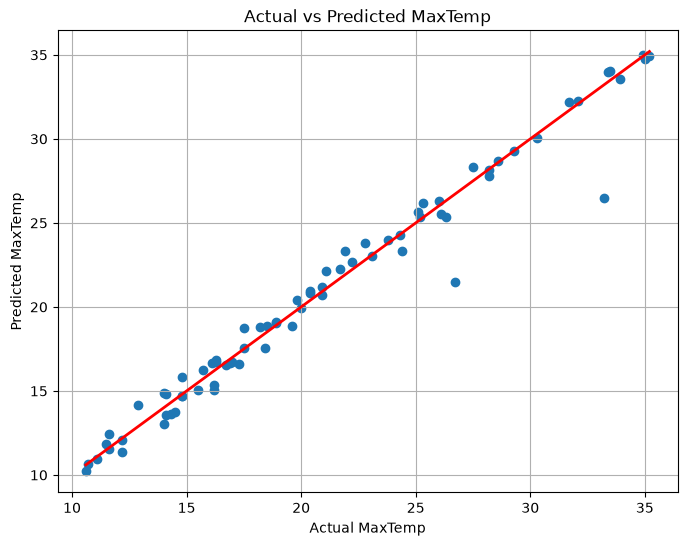

In [33]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2)
plt.xlabel("Actual MaxTemp")
plt.ylabel("Predicted MaxTemp")
plt.title("Actual vs Predicted MaxTemp")
plt.grid(True)
plt.show()

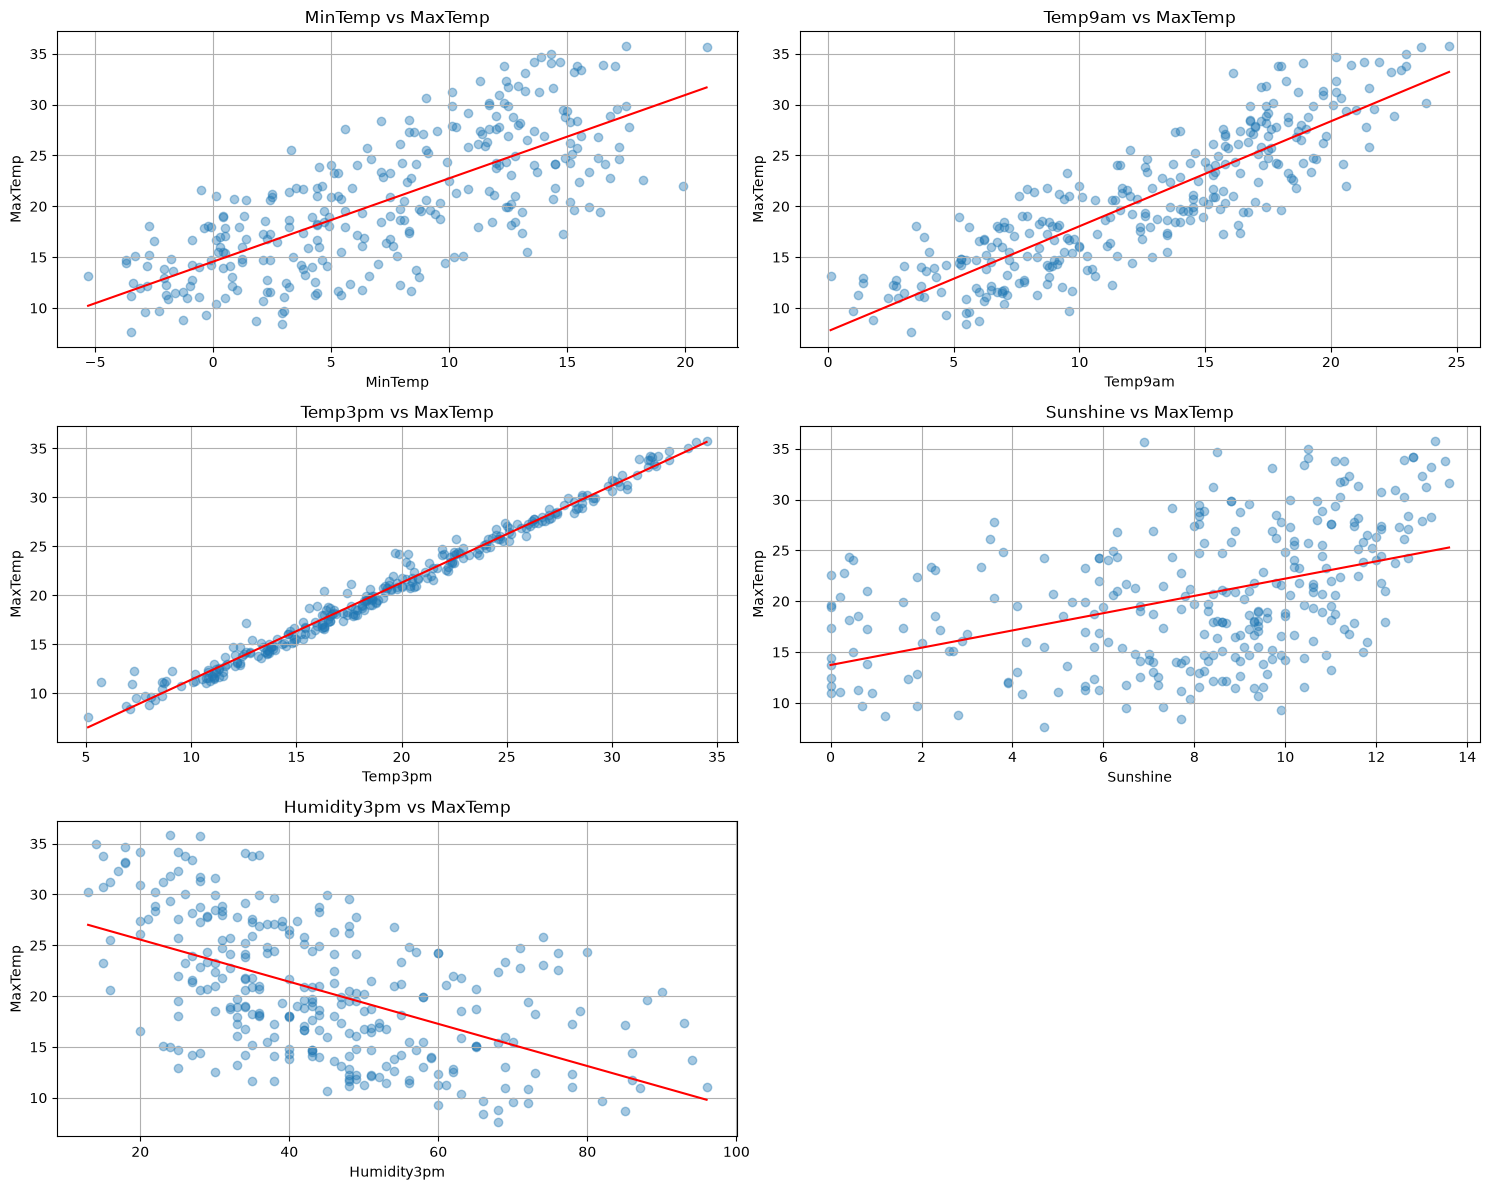

In [34]:
features = ['MinTemp', 'Temp9am', 'Temp3pm', 'Sunshine', 'Humidity3pm']

plt.figure(figsize=(15, 12))
for i, feature in enumerate(features, 1):
    plt.subplot(3, 2, i)
    x = X_train[feature]
    y_plot = y_train
    model_single = LinearRegression()
    model_single.fit(x.values.reshape(-1, 1), y_plot)
    x_line = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
    y_line = model_single.predict(x_line)
    plt.scatter(x, y_plot, alpha=0.4)
    plt.plot(x_line, y_line, color="red")
    plt.title(f'{feature} vs MaxTemp')
    plt.xlabel(feature)
    plt.ylabel("MaxTemp")
    plt.grid(True)
plt.tight_layout()
plt.show()

`Step 11: Predict MaxTemp for New Input Values`

*   Example Hypothetical Weather Data:
    * MinTemp = 12.0
    * Rainfall = 0.0
    * Evaporation = 5.4
    * Sunshine = 9.5
    * WindGustDir = NW
    * WindGustSpeed = 35.0
    * WindDir9am = NW
    * WindDir3pm = NW
    * WindSpeed9am = 11.0
    * WindSpeed3pm = 19.0
    * Humidity9am = 65
    * Humidity3pm = 38
    * Pressure9am = 1018.5
    * Pressure3pm = 1015.2
    * Cloud9am = 2
    * Cloud3pm = 3
    * Temp9am = 16.5
    * Temp3pm = 24.0
    * RainToday = No
    * RISK_MM = 0.0
    * RainTomorrow = No

In [35]:
# Build the zero-filled template matching the trained feature columns
new_data = pd.DataFrame(0, index=[0], columns=X_train.columns)

# Set Numerical Features
new_data['MinTemp'] = 12.0
new_data['Rainfall'] = 0.0
new_data['Evaporation'] = 5.4
new_data['Sunshine'] = 9.5
new_data['WindGustSpeed'] = 35.0
new_data['WindSpeed9am'] = 11.0
new_data['WindSpeed3pm'] = 19.0
new_data['Humidity9am'] = 65
new_data['Humidity3pm'] = 38
new_data['Pressure9am'] = 1018.5
new_data['Pressure3pm'] = 1015.2
new_data['Cloud9am'] = 2
new_data['Cloud3pm'] = 3
new_data['Temp9am'] = 16.5
new_data['Temp3pm'] = 24.0
new_data['RISK_MM'] = 0.0

# Set Categorical Dummy Features (1 for selected category, 0 for others)
new_data['WindGustDir_NW'] = 1
new_data['WindDir9am_NW'] = 1
new_data['WindDir3pm_NW'] = 1
new_data['RainToday_Yes'] = 0
new_data['RainTomorrow_Yes'] = 0

predicted_temp = model.predict(new_data)
print("Predicted MaxTemp:", predicted_temp[0])

Predicted MaxTemp: 24.96729901772565


In [36]:
# rounded output:
print("Predicted MaxTemp:", round(predicted_temp[0], 2))

Predicted MaxTemp: 24.97


*   Note:
*   `predicted_temp[0]`
    * Accesses the first (and only) element of the predicted array.
    * `predicted_temp` is an array because scikit-learn always returns predictions as an array.